# Comparer les entraînements

Un notebook est fait de **cellules** : du texte (comme celle-ci) ou du code. On exécute une cellule à la fois (Maj+Entrée) et son résultat s'affiche juste dessous. Les variables restent en mémoire d'une cellule à l'autre : on peut donc modifier une seule cellule et la relancer, sans tout recalculer.

Ici : lire les CSV de `logs/` et tracer la perte de validation de chaque expérience.

In [6]:
from pathlib import Path
import csv
import matplotlib.pyplot as plt

LOGS = Path("..") / "logs"
ESSAIS = {
    "0 référence (d 256, T 128)": "entrainement_livres.csv",
    "B (T 256)": "entrainement_livres_T256.csv",
    "A (d 384, 6 blocs)": "entrainement_livres_A_d384.csv",
    "D (texte filtré)": "entrainement_livres_D_filtre.csv",
    "P1 (6 blocs, d 256)": "entrainement_livres_P1_6blocs.csv",
    "P2 (d 384, 4 blocs)": "entrainement_livres_P2_d384.csv",
    "P4 (d 384, 8 blocs)": "entrainement_livres_P4_8blocs.csv",
    "P4 + théâtre": "entrainement_livres_P4_theatre.csv",
}

def lire(nom_fichier):
    if not (LOGS / nom_fichier).exists():  # essai pas encore lancé
        return [], []
    with open(LOGS / nom_fichier) as f:
        lignes = list(csv.DictReader(f))
    return [int(l["etape"]) for l in lignes], [float(l["perte_val"]) for l in lignes]

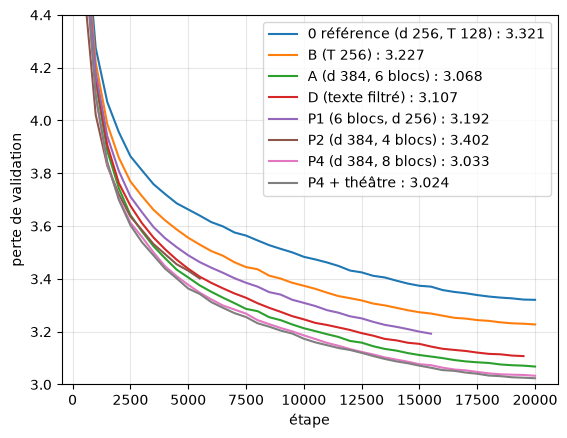

In [9]:
for nom, fichier in ESSAIS.items():
    etapes, pertes = lire(fichier)
    if not pertes:  # entraînement lancé mais pas encore de mesure : on saute
        continue
    plt.plot(etapes, pertes, label=f"{nom} : {min(pertes):.3f}")
plt.ylim(3.0, 4.4)
plt.xlabel("étape")
plt.ylabel("perte de validation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**À essayer** : change `plt.ylim(3.0, 4.8)` en `plt.ylim(3.0, 3.4)` et relance seulement cette cellule : on voit mieux la fin des courbes, sans réentraîner quoi que ce soit.

Un notebook sert à **explorer** (essayer, regarder, ajuster). Un script `.py` sert à **faire tourner** une fois, de bout en bout, de façon reproductible.